# Logistic Regression — Counterfactual Analysis

This notebook studies the **88 legitimate emails** that the Logistic Regression model wrongly classified as phishing. I want to understand which TF-IDF features contributed to those errors and whether reducing their influence could change the model's prediction.

The analysis follows four steps:

1. **Step 12A:** Check that the model's decision scores and probabilities are correct.
2. **Step 12B:** Test which false positives can cross the decision boundary when selected TF-IDF feature values are reduced.
3. **Step 12C:** Find the features that appear repeatedly in these counterfactual cases.
4. **Step 12D:** Look for those features in the original cleaned email text.

This notebook does **not** retrain the model or create new emails. It keeps the original model, data split, TF-IDF settings and decision threshold unchanged.

**Before running:** Run `01_dataset_preparation.ipynb` and `02_official_baseline.ipynb` in the same Colab session.

In [ ]:
import re
import numpy as np
import pandas as pd

from scipy.special import expit
from scipy import sparse
from sklearn.metrics import confusion_matrix

THRESHOLD = 0.50
DECISION_BOUNDARY = 0.0
COUNTERFACTUAL_EPSILON = 1e-9

EXPECTED_TP = 4660
EXPECTED_FP = 88
EXPECTED_FN = 48
EXPECTED_TN = 5920
EXPECTED_FEATURES = 10000

print("Counterfactual-analysis configuration loaded.")


## 1. Check the original model

I use the same Logistic Regression model, training and test split, and 10,000 TF-IDF features as in the official baseline. Nothing is changed here.

In [ ]:
required = [
    "lr_model", "tfidf_vectorizer",
    "X_train_tfidf", "X_test_tfidf",
    "X_train", "X_test", "y_train", "y_test"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing required objects: " + ", ".join(missing)
        + "\nRun notebooks 01 and 02 first in the same runtime."
    )

feature_names = tfidf_vectorizer.get_feature_names_out()
coefficients = lr_model.coef_.ravel()
intercept = float(lr_model.intercept_[0])

model_scores = lr_model.decision_function(X_test_tfidf)
model_probabilities = lr_model.predict_proba(X_test_tfidf)[:, 1]
model_predictions = (model_probabilities >= THRESHOLD).astype(int)

cm = confusion_matrix(y_test, model_predictions)

assert np.array_equal(cm, np.array([[4660, 88], [48, 5920]]))
assert len(feature_names) == EXPECTED_FEATURES

print("Official baseline verified.")
print("Intercept:", intercept)
print("Confusion matrix:")
print(cm)


## 2. Step 12A — Check the model's decision scores

Logistic Regression calculates a score from its intercept and the contributions of the TF-IDF features:

`intercept + Σ(TF-IDF value × coefficient)`

I check these scores and the resulting probabilities against the original model before making any changes to feature values.

In [ ]:
manual_scores = (
    np.asarray(X_test_tfidf.dot(coefficients)).ravel()
    + intercept
)
manual_probabilities = expit(manual_scores)

score_max_difference = float(
    np.max(np.abs(manual_scores - model_scores))
)
probability_max_difference = float(
    np.max(np.abs(manual_probabilities - model_probabilities))
)

print("Manual/model score maximum difference:",
      score_max_difference)
print("Reconstructed/model probability maximum difference:",
      probability_max_difference)

assert np.allclose(manual_scores, model_scores)
assert np.allclose(manual_probabilities, model_probabilities)


In [ ]:
y_test_array = np.asarray(y_test)

fp_positions = np.where(
    (y_test_array == 0) & (model_predictions == 1)
)[0]

assert len(fp_positions) == 88

fp_matrix = X_test_tfidf[fp_positions]
fp_probabilities = model_probabilities[fp_positions]
fp_scores = model_scores[fp_positions]

active_counts = np.diff(fp_matrix.indptr)

phase3_fp_baseline_table = pd.DataFrame({
    "FP_Number": np.arange(1, 89),
    "Test_Position": fp_positions,
    "Original_Index": np.asarray(X_test.index)[fp_positions],
    "Original_Probability": fp_probabilities,
    "Original_Decision_Score": fp_scores,
    "Required_Score_Reduction": fp_scores + COUNTERFACTUAL_EPSILON,
    "Active_TFIDF_Features": active_counts
})

print("False Positive probability:")
print(" min :", fp_probabilities.min())
print(" max :", fp_probabilities.max())
print(" mean:", fp_probabilities.mean())

print("\nFalse Positive decision score:")
print(" min :", fp_scores.min())
print(" max :", fp_scores.max())
print(" mean:", fp_scores.mean())

print("\nActive TF-IDF features per False Positive:")
print(" min :", active_counts.min())
print(" max :", active_counts.max())
print(" mean:", active_counts.mean())

display(phase3_fp_baseline_table.head(10))


### Step 12A — Recorded results

The original experiment gave these values:

| Measure | Recorded result |
|:--|--:|
| Model intercept | 2.1718442046656 |
| Lowest / highest false-positive probability | 0.503689 / 0.991030 |
| Average false-positive probability | 0.704714 |
| Lowest / highest decision score | 0.014756 / 4.704875 |
| Average decision score | 1.078086 |
| Lowest / highest number of active TF-IDF features | 4 / 723 |
| Average number of active TF-IDF features | 94.25 |

These are **recorded results** from the original experiment. This step only checks the model; it does not create counterfactuals.

In [ ]:
assert np.isclose(intercept, 2.1718442046656, atol=1e-12)
assert round(float(fp_probabilities.min()), 6) == 0.503689
assert round(float(fp_probabilities.max()), 6) == 0.991030
assert round(float(fp_probabilities.mean()), 6) == 0.704714
assert round(float(fp_scores.min()), 6) == 0.014756
assert round(float(fp_scores.max()), 6) == 4.704875
assert round(float(fp_scores.mean()), 6) == 1.078086
assert int(active_counts.min()) == 4
assert int(active_counts.max()) == 723
assert np.isclose(float(active_counts.mean()), 94.25)

print("Step 12A locked checkpoint VERIFIED.")


## 3. Step 12B — Test changes to TF-IDF features

For each of the 88 false positives, I identify the features that push the prediction towards phishing. I rank these features by their positive contribution and reduce their values, starting with the strongest. I then check whether the model changes its prediction to legitimate.

This is a **greedy method**: it follows a fixed ranking of features. It does not prove that I have found the best possible text edit. A case called *not feasible* here simply means this particular method could not change its prediction.

In [ ]:
positive_coefficient_count = int(np.sum(coefficients > 0))
print("Features with positive LR coefficient:",
      positive_coefficient_count)
assert positive_coefficient_count == 4734


In [ ]:
summary_rows = []
detail_rows = []
modified_vectors = {}

for fp_number, test_position in enumerate(fp_positions, start=1):
    row = X_test_tfidf[test_position].tocsr()
    score = float(model_scores[test_position])
    probability = float(model_probabilities[test_position])
    required = score + COUNTERFACTUAL_EPSILON

    indices = row.indices
    values = row.data
    coeffs = coefficients[indices]
    contributions = values * coeffs

    positive_mask = contributions > 0
    p_indices = indices[positive_mask]
    p_values = values[positive_mask]
    p_coeffs = coeffs[positive_mask]
    p_contrib = contributions[positive_mask]

    order = np.argsort(-p_contrib)
    p_indices = p_indices[order]
    p_values = p_values[order]
    p_coeffs = p_coeffs[order]
    p_contrib = p_contrib[order]

    feasible = float(p_contrib.sum()) > required

    if not feasible:
        summary_rows.append({
            "FP_Number": fp_number,
            "Test_Position": int(test_position),
            "Original_Probability": probability,
            "Original_Decision_Score": score,
            "Required_Score_Reduction": required,
            "Positive_Active_Features": len(p_indices),
            "Counterfactual_Feasible": False,
            "Minimal_Feature_Count": np.nan,
            "Full_Removals": np.nan,
            "Partial_Final_Feature": False,
            "Counterfactual_Probability": np.nan,
            "Counterfactual_Decision_Score": np.nan,
            "Prediction_Flipped": False
        })
        continue

    modified = row.copy().tolil()
    cumulative = 0.0
    selected = []

    for rank, (idx, old_value, coef, contribution) in enumerate(
        zip(p_indices, p_values, p_coeffs, p_contrib), start=1
    ):
        remaining = required - cumulative

        if contribution > remaining:
            reduction_value = remaining / coef
            new_value = max(0.0, old_value - reduction_value)
            achieved = (old_value - new_value) * coef
            fully_removed = False
            boundary_feature = True
        else:
            new_value = 0.0
            achieved = contribution
            fully_removed = True
            boundary_feature = False

        modified[0, idx] = new_value
        cumulative += achieved

        selected.append({
            "Counterfactual_Feature_Rank": rank,
            "Feature": feature_names[idx],
            "TFIDF_Index": int(idx),
            "Original_TFIDF_Value": float(old_value),
            "New_TFIDF_Value": float(new_value),
            "Fraction_Removed": float(
                (old_value - new_value) / old_value
            ),
            "LR_Coefficient": float(coef),
            "Original_Phishing_Contribution": float(contribution),
            "Achieved_Score_Reduction": float(achieved),
            "Fully_Removed": bool(fully_removed),
            "Final_Boundary_Feature": bool(boundary_feature)
        })

        if cumulative >= required:
            break

    modified = modified.tocsr()
    cf_score = float(lr_model.decision_function(modified)[0])
    cf_probability = float(
        lr_model.predict_proba(modified)[0, 1]
    )
    cf_prediction = int(cf_probability >= THRESHOLD)
    flipped = cf_prediction == 0

    modified_vectors[fp_number] = modified

    for item in selected:
        detail_rows.append({
            "FP_Number": fp_number,
            "Test_Position": int(test_position),
            **item
        })

    summary_rows.append({
        "FP_Number": fp_number,
        "Test_Position": int(test_position),
        "Original_Probability": probability,
        "Original_Decision_Score": score,
        "Required_Score_Reduction": required,
        "Positive_Active_Features": len(p_indices),
        "Counterfactual_Feasible": True,
        "Minimal_Feature_Count": len(selected),
        "Full_Removals": sum(x["Fully_Removed"] for x in selected),
        "Partial_Final_Feature":
            any(x["Final_Boundary_Feature"] for x in selected),
        "Counterfactual_Probability": cf_probability,
        "Counterfactual_Decision_Score": cf_score,
        "Prediction_Flipped": flipped
    })

counterfactual_summary = pd.DataFrame(summary_rows)
counterfactual_details = pd.DataFrame(detail_rows)

feasible_summary = counterfactual_summary[
    counterfactual_summary["Counterfactual_Feasible"]
].copy()

print("Total baseline FPs analysed:", len(counterfactual_summary))
print("Feasible:", len(feasible_summary))
print("Infeasible:", 88 - len(feasible_summary))
print("Verified flips:",
      int(feasible_summary["Prediction_Flipped"].sum()))


In [ ]:
assert len(feasible_summary) == 56
assert (88 - len(feasible_summary)) == 32
assert int(feasible_summary["Prediction_Flipped"].sum()) == 56
assert len(counterfactual_details) == 411

sizes = feasible_summary["Minimal_Feature_Count"].astype(int)

print("Minimum:", sizes.min())
print("Maximum:", sizes.max())
print("Mean   :", sizes.mean())
print("Median :", sizes.median())

assert sizes.min() == 1
assert sizes.max() == 61
assert np.isclose(sizes.mean(), 7.339285714285714)
assert sizes.median() == 3.5

size_distribution = (
    sizes.value_counts()
    .sort_index()
    .rename_axis("Minimal_Feature_Count")
    .reset_index(name="FP_Count")
)
size_distribution["Percentage_of_Feasible_FPs"] = (
    100 * size_distribution["FP_Count"] / 56
)

display(size_distribution)


### Table 4.1 — Results of the feature-level counterfactual test

| Result | Number of emails | Share of 88 false positives |
|:--|--:|--:|
| Prediction could be changed by this method | 56 | 63.64% |
| Prediction could not be changed by this method | 32 | 36.36% |
| **Total** | **88** | **100.00%** |

*Source: recorded Step 12B results.*

This means that reducing selected TF-IDF values changed the model's prediction for 56 cases. **It does not mean that 56 real emails were successfully edited.** Figure 4.1 shows the same comparison.

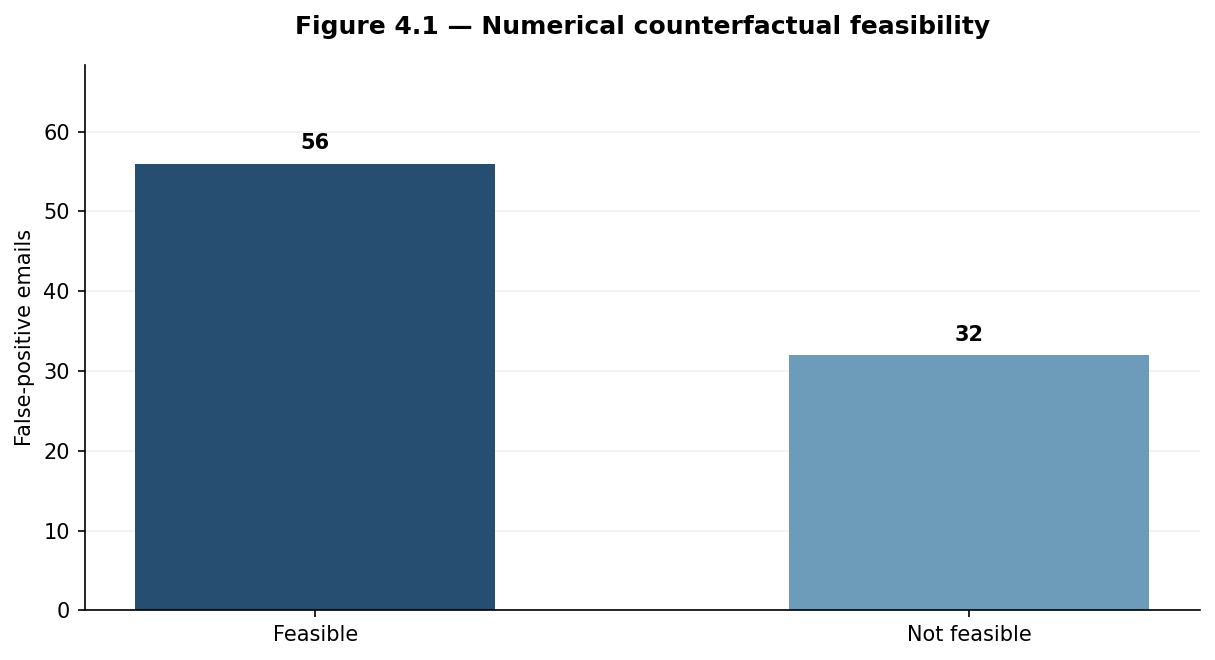

In [ ]:
# Recorded checkpoint visualization: Figure 4.1 — Numerical counterfactual feasibility
# The values are the locked aggregate counts documented in this notebook.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8.2, 4.5))
labels = ['Feasible', 'Not feasible']
counts = [56, 32]
bars = ax.bar(labels, counts, color="steelblue", width=0.55)
ax.set_title('Figure 4.1 — Numerical counterfactual feasibility')
ax.set_ylabel('False-positive emails')
ax.spines[["top", "right"]].set_visible(False)
for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

### Example — False-positive email 2

For email 2, the numerical test first reduced the feature `com` and then partly reduced `net`. This was enough to change the prediction in TF-IDF space.

The partial reduction of `net` is a change to a numerical feature value, **not** a claim that the same percentage of words was deleted from the email.

In [ ]:
fp2 = counterfactual_details[
    counterfactual_details["FP_Number"] == 2
].copy()

display(fp2)

fp2_summary = counterfactual_summary[
    counterfactual_summary["FP_Number"] == 2
].iloc[0]

assert np.isclose(
    fp2_summary["Original_Probability"], 0.57640502,
    atol=1e-8
)
assert np.isclose(
    fp2_summary["Original_Decision_Score"], 0.30803282,
    atol=1e-8
)

assert fp2["Feature"].tolist() == ["com", "net"]

print("FP2 counterfactual example VERIFIED.")


## 4. Step 12C — Find features that appear repeatedly

The 56 feasible cases produced **411 feature-level records**. I group these records to see which features appear across different cases.

To rank the features, the notebook uses this score:

`number of false-positive cases × average score reduction × model coefficient`

This score helps me order the features for analysis. It is **not** a phishing probability and does not change the model.

In [ ]:
grouped = (
    counterfactual_details
    .groupby(["TFIDF_Index", "Feature"], as_index=False)
    .agg(
        CF_FP_Frequency=("FP_Number", "nunique"),
        CF_Total_Occurrences=("FP_Number", "size"),
        Mean_Achieved_Score_Reduction=(
            "Achieved_Score_Reduction", "mean"
        ),
        Total_Achieved_Score_Reduction=(
            "Achieved_Score_Reduction", "sum"
        ),
        LR_Coefficient=("LR_Coefficient", "first"),
        Complete_Removal_Count=("Fully_Removed", "sum"),
        Partial_Reduction_Count=(
            "Fully_Removed", lambda x: int((~x.astype(bool)).sum())
        ),
        Boundary_Feature_Count=("Final_Boundary_Feature", "sum")
    )
)

grouped["Percentage_of_Feasible_FPs"] = (
    100 * grouped["CF_FP_Frequency"] / 56
)

grouped["Counterfactual_Evidence_Score"] = (
    grouped["CF_FP_Frequency"]
    * grouped["Mean_Achieved_Score_Reduction"]
    * grouped["LR_Coefficient"]
)

counterfactual_feature_ranking = grouped.sort_values(
    "Counterfactual_Evidence_Score",
    ascending=False
).reset_index(drop=True)

counterfactual_feature_ranking.insert(
    0, "Counterfactual_Rank",
    np.arange(1, len(counterfactual_feature_ranking) + 1)
)

recurring_features = counterfactual_feature_ranking[
    counterfactual_feature_ranking["CF_FP_Frequency"] >= 3
].copy()

print("Feature-level rows:", len(counterfactual_details))
print("Unique counterfactual features:",
      len(counterfactual_feature_ranking))
print("Recurring features (>=3 FPs):",
      len(recurring_features))

assert len(counterfactual_details) == 411
assert len(counterfactual_feature_ranking) == 268
assert len(recurring_features) == 31

display(counterfactual_feature_ranking.head(30))


The five highest-ranked features in the recorded analysis are `escapelong escapelong`, `com`, `net`, `great` and `online`.

Although `com` appears more often, `escapelong escapelong` ranks first because the ranking also considers the size of the score reduction and the model coefficient.

In [ ]:
recurring_names = set(recurring_features["Feature"])

def coverage_for_top_n(n):
    selected = set(
        recurring_features.head(n)["Feature"].tolist()
    )
    covered = (
        counterfactual_details[
            counterfactual_details["Feature"].isin(selected)
        ]["FP_Number"].nunique()
    )
    return covered, 100 * covered / 56

coverage_rows = []
for n in [5, 10, 20, 30]:
    covered, percentage = coverage_for_top_n(n)
    coverage_rows.append({
        "Top_N_Recurring_Features": n,
        "Covered_Feasible_FPs": covered,
        "Total_Feasible_FPs": 56,
        "Coverage_Percent": percentage
    })

coverage_table = pd.DataFrame(coverage_rows)
display(coverage_table)

assert coverage_table["Covered_Feasible_FPs"].tolist() == [
    26, 37, 45, 46
]

print("Coverage checkpoint VERIFIED.")


### Table 4.2 — Coverage of the feasible cases

| Number of top-ranked features considered | Cases containing at least one of these features | Share of 56 feasible cases |
|:--|--:|--:|
| Top 5 | 26 | 46.43% |
| Top 10 | 37 | 66.07% |
| Top 20 | 45 | 80.36% |
| Top 30 | 46 | 82.14% |

*Source: recorded Step 12C results.*

For example, **26 of the 56 cases** contain at least one feature from the top five. This does **not** mean those five features alone would change all 26 predictions. Figure 4.2 illustrates the coverage.

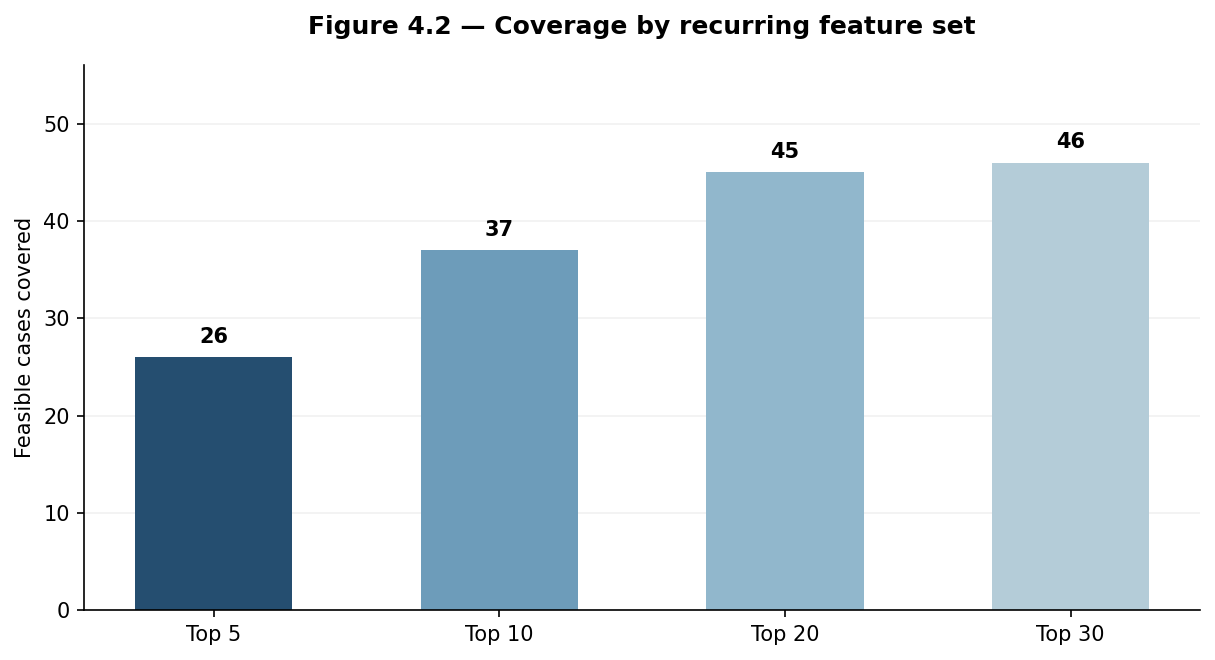

In [ ]:
# Recorded checkpoint visualization: Figure 4.2 — Coverage by recurring feature set
# The values are the locked aggregate counts documented in this notebook.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8.2, 4.5))
labels = ['Top 5', 'Top 10', 'Top 20', 'Top 30']
counts = [26, 37, 45, 46]
bars = ax.bar(labels, counts, color="steelblue", width=0.55)
ax.set_title('Figure 4.2 — Coverage by recurring feature set')
ax.set_ylabel('Feasible cases covered')
ax.spines[["top", "right"]].set_visible(False)
for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

A case counts as covered when it contains **at least one** feature from the selected group. Coverage shows how common those features are, not whether the group alone is enough to change a prediction.

## 5. Step 12D — Find the features in the email text

The previous steps worked with numbers in TF-IDF vectors. Here, I check where the selected features appear in the original cleaned emails.

For each match, the notebook records the surrounding text, up to **35 words on either side**. This helps prepare for later text-editing experiments. **No new email is created in this step.**

In [ ]:
def feature_regex(feature):
    # Match the TF-IDF n-gram as consecutive word tokens.
    tokens = feature.split()
    return re.compile(
        r"(?<!\w)" + r"\s+".join(
            re.escape(t) for t in tokens
        ) + r"(?!\w)",
        flags=re.IGNORECASE
    )

def word_context(text, start, end, window=35):
    # Determine word spans in the complete cleaned email.
    words = list(re.finditer(r"\S+", text))
    if not words:
        return ""

    hit_indices = [
        i for i, w in enumerate(words)
        if not (w.end() <= start or w.start() >= end)
    ]
    if not hit_indices:
        return ""

    left = max(0, hit_indices[0] - window)
    right = min(len(words), hit_indices[-1] + window + 1)
    return " ".join(w.group(0) for w in words[left:right])

test_text_array = np.asarray(X_test)

mapping_rows = []
template_rows = []

for _, summary_row in feasible_summary.iterrows():
    fp_number = int(summary_row["FP_Number"])
    test_position = int(summary_row["Test_Position"])
    text = str(test_text_array[test_position])

    details = counterfactual_details[
        counterfactual_details["FP_Number"] == fp_number
    ].sort_values("Counterfactual_Feature_Rank")

    matched_feature_count = 0
    unmatched_feature_count = 0

    for _, d in details.iterrows():
        feature = d["Feature"]
        matches = list(feature_regex(feature).finditer(text))

        if matches:
            matched_feature_count += 1
            for occurrence_number, match in enumerate(matches, start=1):
                mapping_rows.append({
                    "FP_Number": fp_number,
                    "Test_Position": test_position,
                    "Feature": feature,
                    "Counterfactual_Feature_Rank":
                        int(d["Counterfactual_Feature_Rank"]),
                    "Occurrence_Number": occurrence_number,
                    "Matched": True,
                    "Match_Start": match.start(),
                    "Match_End": match.end(),
                    "Context_35_Words_Each_Side":
                        word_context(
                            text, match.start(), match.end(), 35
                        )
                })
        else:
            unmatched_feature_count += 1
            mapping_rows.append({
                "FP_Number": fp_number,
                "Test_Position": test_position,
                "Feature": feature,
                "Counterfactual_Feature_Rank":
                    int(d["Counterfactual_Feature_Rank"]),
                "Occurrence_Number": 0,
                "Matched": False,
                "Match_Start": np.nan,
                "Match_End": np.nan,
                "Context_35_Words_Each_Side": ""
            })

    minimal_features = " | ".join(details["Feature"].tolist())
    recurring_cf = " | ".join(
        [f for f in details["Feature"].tolist()
         if f in recurring_names]
    )

    template_rows.append({
        "FP_Number": fp_number,
        "Test_Position": test_position,
        "Original_Probability":
            float(summary_row["Original_Probability"]),
        "Minimal_Feature_Count":
            int(summary_row["Minimal_Feature_Count"]),
        "Minimal_Counterfactual_Features": minimal_features,
        "Recurring_CF_Features": recurring_cf,
        "Matched_Feature_Count": matched_feature_count,
        "Unmatched_Feature_Count": unmatched_feature_count,
        "Original_Text": text
    })

mapping_table = pd.DataFrame(mapping_rows)
counterfactual_templates = pd.DataFrame(template_rows)

matched_occurrence_rows = int(mapping_table["Matched"].sum())
unmatched_feature_rows = int((~mapping_table["Matched"]).sum())
fully_mapped_templates = int(
    (counterfactual_templates["Unmatched_Feature_Count"] == 0).sum()
)
partially_unmatched_templates = int(
    (counterfactual_templates["Unmatched_Feature_Count"] > 0).sum()
)

print("Matched feature-occurrence rows:",
      matched_occurrence_rows)
print("Unmatched feature rows:",
      unmatched_feature_rows)
print("Fully mapped templates:",
      fully_mapped_templates)
print("Templates with >=1 unmatched feature:",
      partially_unmatched_templates)

display(counterfactual_templates.head(10))


### Step 12D — Recorded results

The original analysis found **1,340 matched text occurrences** and **5 unmatched feature records**. Of the 56 feasible cases, **52** had all selected features mapped to text, while **4** had at least one unmatched feature.

One feature can appear more than once in an email. This is why the number of text occurrences is larger than the number of feature-level records.

In [ ]:
# Exact text-token mapping can be affected if the text object passed from
# notebook 01 is not the same cleaned representation used in the original
# Step 12D. These assertions intentionally protect the locked experiment.
assert matched_occurrence_rows == 1340, (
    "Step 12D mapping count differs from the locked experiment. "
    "Confirm that X_test contains the exact cleaned text representation "
    "from notebook 01."
)
assert unmatched_feature_rows == 5
assert fully_mapped_templates == 52
assert partially_unmatched_templates == 4

print("Step 12D locked checkpoint VERIFIED.")


### Table 4.3 — Matching the selected features to email text

| Measure | Recorded count |
|:--|--:|
| Matched occurrences in the email text | 1,340 |
| Feature records without a text match | 5 |
| Cases with all selected features matched | 52 |
| Cases with at least one unmatched feature | 4 |

*Source: recorded Step 12D results.*

The last two rows refer to the **56 feasible cases** (52 + 4). The first two rows count feature matches or records, not emails. Figure 4.3 compares the fully and partly mapped cases.

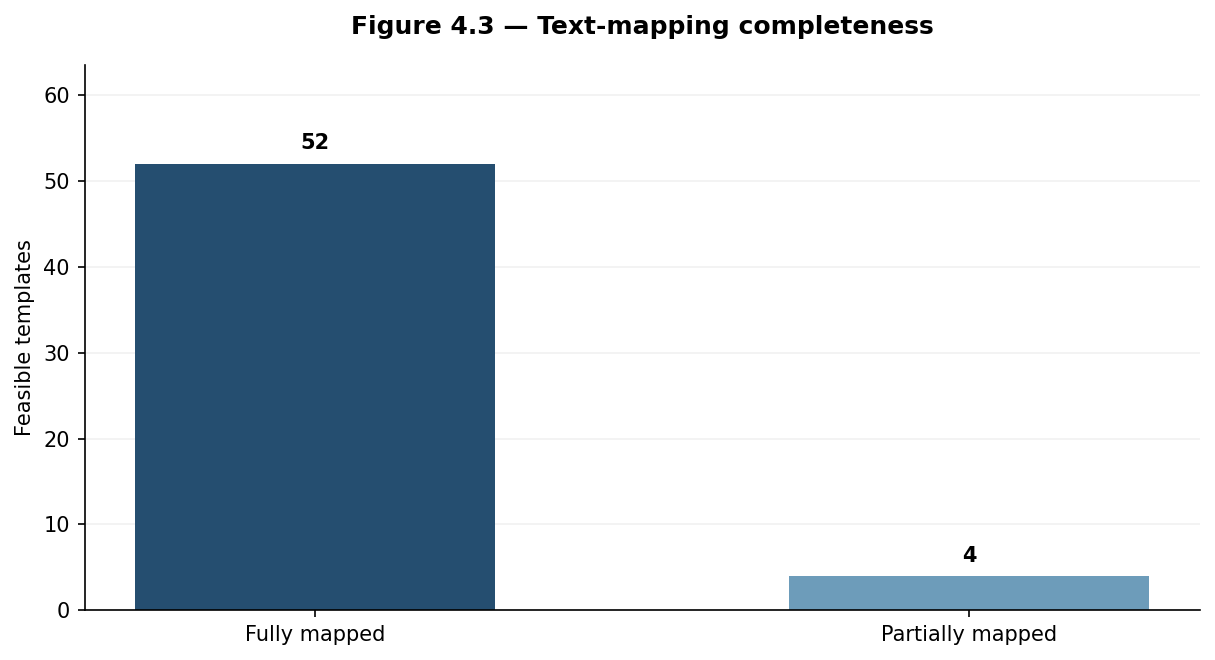

In [ ]:
# Recorded checkpoint visualization: Figure 4.3 — Text-mapping completeness
# The values are the locked aggregate counts documented in this notebook.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8.2, 4.5))
labels = ['Fully mapped', 'Partially mapped']
counts = [52, 4]
bars = ax.bar(labels, counts, color="steelblue", width=0.55)
ax.set_title('Figure 4.3 — Text-mapping completeness')
ax.set_ylabel('Feasible templates')
ax.spines[["top", "right"]].set_visible(False)
for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 6. Example — Matching features in false-positive email 2

In the numerical test for email 2, `com` was reduced fully and `net` was reduced by about **26.25% of its TF-IDF value**. Both features were found in the email text.

This does **not** mean that 26.25% of the written occurrences of `net` were removed.

In [ ]:
fp2_mapping_details = counterfactual_details[
    counterfactual_details["FP_Number"] == 2
][[
    "Counterfactual_Feature_Rank",
    "Feature",
    "Fraction_Removed",
    "Fully_Removed",
    "Final_Boundary_Feature"
]].copy()

fp2_mapping_details["Recurring_Feature"] = (
    fp2_mapping_details["Feature"].isin(recurring_names)
)

fp2_mapping_details["Text_Match"] = (
    fp2_mapping_details["Feature"].isin(
        mapping_table[
            (mapping_table["FP_Number"] == 2)
            & (mapping_table["Matched"])
        ]["Feature"]
    )
)

display(fp2_mapping_details)

assert fp2_mapping_details["Feature"].tolist() == ["com", "net"]
assert np.isclose(
    fp2_mapping_details.iloc[0]["Fraction_Removed"], 1.0
)
assert np.isclose(
    fp2_mapping_details.iloc[1]["Fraction_Removed"],
    0.262539,
    atol=1e-6
)

print("FP2 feature-to-text mapping example VERIFIED.")


## 7. Save and review the evidence tables

The table below is **already included in the notebook**, so you can read it on GitHub without running the code. It summarises the recorded results from Steps 12A–12D.

### Table 4.4 — Summary of the counterfactual analysis

| Measure | Recorded result | What it means |
|:--|--:|:--|
| False-positive emails examined | 88 | Legitimate emails wrongly classified as phishing |
| Feasible feature-level counterfactuals | 56 | Predictions changed by the numerical feature-reduction method |
| Not feasible with this method | 32 | Predictions did not change using this method |
| Feature-level counterfactual records | 411 | Selected feature changes recorded across the feasible cases |
| Unique selected features | 268 | Different TF-IDF features in the counterfactual records |
| Recurring features | 31 | Features identified as recurring in the recorded analysis |
| Cases with all selected features matched to text | 52 | Feasible cases with complete text mapping |
| Cases with unmatched features | 4 | Feasible cases needing further mapping work |

*Source: recorded checkpoints from the original experiment. These values are not newly calculated results.*

### Table 4.5 — Evidence files saved by this notebook

| Step | Saved evidence | Number of CSV files |
|:--|:--|--:|
| 12A | False-positive baseline records | 1 |
| 12B | Counterfactual summary, feature details and feature-count distribution | 3 |
| 12C | Feature ranking, recurring features and coverage | 3 |
| 12D | Text-feature mapping and text templates | 2 |
| **Total** | | **9** |

The next code cell saves these nine CSV files and **shows more detailed tables when the notebook is run**. Those detailed tables are not embedded yet, so they will not appear on GitHub until the notebook is executed and saved with its outputs.

**Privacy:** Some saved CSV files may contain original email text. Check them before sharing them publicly.

In [ ]:
OUTPUT_FOLDER = "counterfactual_analysis_outputs"

import os
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

phase3_fp_baseline_table.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12A_Official_88_FP_Counterfactual_Baseline.csv"
    ),
    index=False
)

counterfactual_summary.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12B_Counterfactual_Summary.csv"
    ),
    index=False
)

counterfactual_details.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12B_Counterfactual_Feature_Details.csv"
    ),
    index=False
)

size_distribution.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12B_Minimal_Size_Distribution.csv"
    ),
    index=False
)

counterfactual_feature_ranking.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12C_Counterfactual_Feature_Ranking.csv"
    ),
    index=False
)

recurring_features.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12C_Recurring_Features.csv"
    ),
    index=False
)

coverage_table.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12C_Coverage.csv"
    ),
    index=False
)

mapping_table.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12D_Feature_Text_Mapping.csv"
    ),
    index=False
)

counterfactual_templates.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "Step12D_Counterfactual_Text_Templates.csv"
    ),
    index=False
)

print("Counterfactual evidence saved to:", OUTPUT_FOLDER)

# ------------------------------------------------------------
# Section 7: display reproducible evidence tables in notebook
# ------------------------------------------------------------
from IPython.display import display

public_previews = [
    ("Step 12A — False Positive baseline (first 10)", phase3_fp_baseline_table, 10),
    ("Step 12B — Counterfactual summary (first 10)", counterfactual_summary, 10),
    ("Step 12B — Minimal feature-count distribution", size_distribution, 30),
    ("Step 12C — Top 20 ranked counterfactual features", counterfactual_feature_ranking, 20),
    ("Step 12C — Recurring features (first 20)", recurring_features, 20),
    ("Step 12C — Feature coverage", coverage_table, 20),
]

for title, frame, max_rows in public_previews:
    print("\n" + "=" * 65)
    print(title)
    print(f"Total rows: {len(frame)} | Columns: {len(frame.columns)}")
    display(frame.head(max_rows).reset_index(drop=True))

# Only show aggregated mapping statistics, never email text.
mapping_summary = pd.DataFrame([
    {"Measure": "Official false positives", "Count": len(fp_positions)},
    {"Measure": "Feasible feature-level counterfactuals", "Count": len(feasible_summary)},
    {"Measure": "Feature-level counterfactual rows", "Count": len(counterfactual_details)},
    {"Measure": "Matched text occurrences", "Count": matched_occurrence_rows},
    {"Measure": "Unmatched feature rows", "Count": unmatched_feature_rows},
    {"Measure": "Fully mapped text templates", "Count": fully_mapped_templates},
    {"Measure": "Templates with unmatched features", "Count": partially_unmatched_templates},
])
print("\nStep 12D — Text mapping summary (no email text)")
display(mapping_summary)

# Confirm exported files exist and match in-memory row counts.
exported_tables = [
    ("Step12A_Official_88_FP_Counterfactual_Baseline.csv", phase3_fp_baseline_table),
    ("Step12B_Counterfactual_Summary.csv", counterfactual_summary),
    ("Step12B_Counterfactual_Feature_Details.csv", counterfactual_details),
    ("Step12B_Minimal_Size_Distribution.csv", size_distribution),
    ("Step12C_Counterfactual_Feature_Ranking.csv", counterfactual_feature_ranking),
    ("Step12C_Recurring_Features.csv", recurring_features),
    ("Step12C_Coverage.csv", coverage_table),
    ("Step12D_Feature_Text_Mapping.csv", mapping_table),
    ("Step12D_Counterfactual_Text_Templates.csv", counterfactual_templates),
]

verification_rows = []
for filename, original in exported_tables:
    path = os.path.join(OUTPUT_FOLDER, filename)
    exists = os.path.isfile(path)
    saved_rows = len(pd.read_csv(path)) if exists else None
    verified = exists and saved_rows == len(original)
    verification_rows.append({
        "File": filename,
        "Expected_Rows": len(original),
        "Saved_Rows": saved_rows,
        "Verified": verified,
    })

verification_table = pd.DataFrame(verification_rows)
print("\nSection 7 — CSV export verification")
display(verification_table)
assert verification_table["Verified"].all(), "An exported evidence table failed verification."
print("All nine CSV exports match the in-memory row counts. No model retraining performed.")


### Figures 4.4 and 4.5 — Generated when the notebook runs

The next code cell creates two additional figures from the actual experiment data: the number of features needed per case and the 20 most frequent counterfactual features. These figures **are not embedded yet**. Run the notebook and save its outputs to make them visible on GitHub.

In [ ]:
import matplotlib.pyplot as plt

# Figure 4.4: distribution of the minimum number of features modified.
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(size_distribution["Minimal_Feature_Count"],
       size_distribution["FP_Count"], color="steelblue")
ax.set(title="Figure 4.4 — Minimum feature count per feasible counterfactual",
       xlabel="Minimum TF-IDF features modified", ylabel="False-positive cases")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_FOLDER, "Figure_4_4_Feature_Count_Distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

# Figure 4.5: actual occurrence frequency of the top-ranked features.
top = counterfactual_feature_ranking.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["Feature"], top["CF_FP_Frequency"], color="steelblue")
ax.set(title="Figure 4.5 — Top-ranked counterfactual features",
       xlabel="Feasible false-positive cases containing feature", ylabel="TF-IDF feature")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_FOLDER, "Figure_4_5_Top_Feature_Frequencies.png"), dpi=300, bbox_inches="tight")
plt.show()


## What this notebook found

I started with **88 false positives**. The numerical method could change the prediction for **56** of them. These cases produced **411 feature-level records**, including **268 different features**. The analysis identified **31 recurring features**, and **52** of the feasible cases had all selected features matched to the original email text.

The remaining 32 cases could not be changed **using this specific method**. This does not rule out other approaches.

No new email text has been generated here. The next notebook, `05_synthetic_variant_generation.ipynb`, deals with that stage.

The summary tables and embedded figures show recorded results. A complete rerun is still needed to check the generated outputs against the original experiment.